In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.model_selection import StratifiedGroupKFold

sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 150)

print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
PROJECT_DIR = Path("..")

DATA_DIR = PROJECT_DIR / "data"
RAW_DIR = DATA_DIR / "raw"
PROCESSED_DIR = DATA_DIR / "processed"

FIGURE_DIR = PROJECT_DIR / "figures"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

DATA_PATH = RAW_DIR / "creditcard.csv"

print("Dataset path:", DATA_PATH.resolve())
print("Processed directory:", PROCESSED_DIR.resolve())

Dataset path: /Users/jasmithav/isfe_creditcard_project/data/raw/creditcard.csv
Processed directory: /Users/jasmithav/isfe_creditcard_project/data/processed


In [4]:
df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully.
Dataset shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [5]:
TARGET = "Class"

FEATURES = [
    column for column in df.columns
    if column != TARGET
]

X = df[FEATURES].copy()
y = df[TARGET].copy()

print("Number of features:", len(FEATURES))
print("Target variable:", TARGET)

print("\nFeature matrix:", X.shape)
print("Target vector:", y.shape)

print("\nClass distribution:")
print(y.value_counts().sort_index())

Number of features: 30
Target variable: Class

Feature matrix: (284807, 30)
Target vector: (284807,)

Class distribution:
Class
0    284315
1       492
Name: count, dtype: int64


In [6]:
print("Missing values:", df.isnull().sum().sum())

print("Duplicate rows:", df.duplicated().sum())

print("Unique target values:", sorted(y.unique()))

print("Data types:")
print(df.dtypes.value_counts())

assert df.isnull().sum().sum() == 0
assert set(y.unique()) == {0, 1}
assert len(FEATURES) == 30

print("\nInitial integrity checks passed.")

Missing values: 0
Duplicate rows: 1081
Unique target values: [np.int64(0), np.int64(1)]
Data types:
float64    30
int64       1
Name: count, dtype: int64

Initial integrity checks passed.


In [7]:
groups = pd.util.hash_pandas_object(
    df,
    index=False
).to_numpy()

unique_group_ids = np.unique(groups)

print("Total observations:", len(df))

print("Unique duplicate groups:", len(unique_group_ids))

print("Excess duplicate occurrences:",
      len(df) - len(unique_group_ids))

Total observations: 284807
Unique duplicate groups: 283726
Excess duplicate occurrences: 1081


In [8]:
group_sizes = (
    pd.Series(groups)
    .value_counts()
)

duplicate_group_sizes = group_sizes[
    group_sizes > 1
]

print("Unique duplicate groups:",
      len(duplicate_group_sizes))

print("\nDuplicate group frequencies:")

print(
    duplicate_group_sizes
    .value_counts()
    .sort_index()
)

print("\nTotal rows belonging to duplicate groups:",
      duplicate_group_sizes.sum())

Unique duplicate groups: 773

Duplicate group frequencies:
count
2     611
3      66
4      81
5      10
6       1
9       2
18      2
Name: count, dtype: int64

Total rows belonging to duplicate groups: 1854


In [9]:
outer_splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

development_idx, test_idx = next(
    outer_splitter.split(X, y, groups)
)

print("Development observations:", len(development_idx))
print("Test observations:", len(test_idx))

Development observations: 227846
Test observations: 56961


In [11]:
X_dev = X.iloc[development_idx].copy()
y_dev = y.iloc[development_idx].copy()

groups_dev = groups[development_idx]

print("Development feature shape:", X_dev.shape)
print("Development target shape:", y_dev.shape)

Development feature shape: (227846, 30)
Development target shape: (227846,)


In [12]:
inner_splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

train_relative_idx, val_relative_idx = next(
    inner_splitter.split(
        X_dev,
        y_dev,
        groups_dev
    )
)

train_idx = development_idx[train_relative_idx]
val_idx = development_idx[val_relative_idx]

print("Training indices:", len(train_idx))
print("Validation indices:", len(val_idx))

Training indices: 182276
Validation indices: 45570


In [13]:
X_train = X.iloc[train_idx].copy()
X_val = X.iloc[val_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_val = y.iloc[val_idx].copy()
y_test = y.iloc[test_idx].copy()

print("TRAINING:", X_train.shape)
print("VALIDATION:", X_val.shape)
print("TESTING:", X_test.shape)

TRAINING: (182276, 30)
VALIDATION: (45570, 30)
TESTING: (56961, 30)


In [14]:
def show_distribution(name, target):

    counts = target.value_counts().sort_index()

    percentages = (
        target.value_counts(normalize=True)
        .sort_index() * 100
    )

    result = pd.DataFrame({
        "Count": counts,
        "Percentage": percentages
    })

    print(f"\n{name}")
    display(result)


show_distribution("TRAINING", y_train)

show_distribution("VALIDATION", y_val)

show_distribution("TEST", y_test)


TRAINING


,Count,Percentage
Class,,
0,181961,99.827185
1,315,0.172815



VALIDATION


,Count,Percentage
Class,,
0,45491,99.82664
1,79,0.17336



TEST


,Count,Percentage
Class,,
0,56863,99.827952
1,98,0.172048


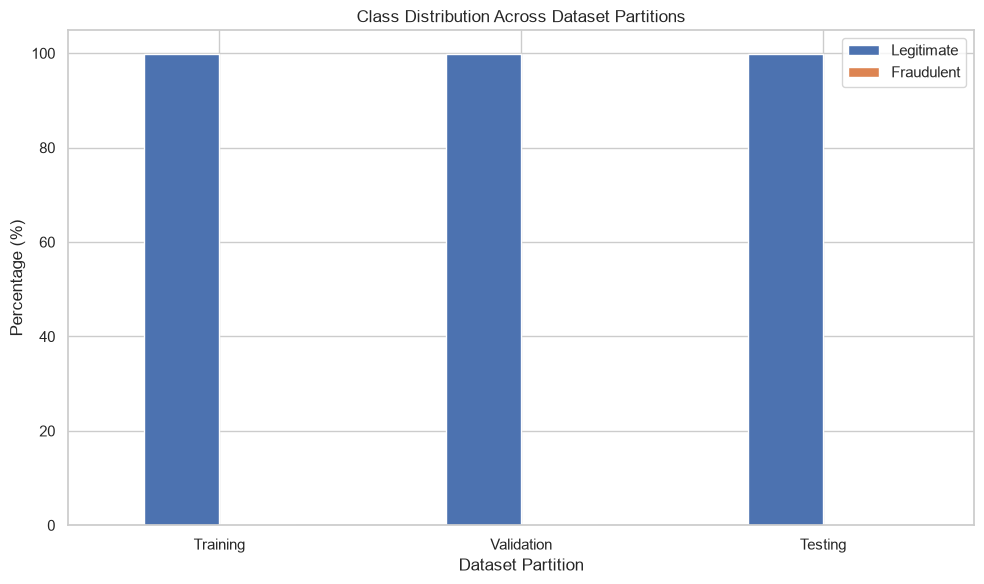

In [15]:
split_data = pd.DataFrame({
    "Training": y_train.value_counts(normalize=True) * 100,
    "Validation": y_val.value_counts(normalize=True) * 100,
    "Testing": y_test.value_counts(normalize=True) * 100
}).T

ax = split_data.plot(
    kind="bar",
    figsize=(10, 6)
)

ax.set_title("Class Distribution Across Dataset Partitions")
ax.set_xlabel("Dataset Partition")
ax.set_ylabel("Percentage (%)")
ax.legend(["Legitimate", "Fraudulent"])

plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(FIGURE_DIR / "split_class_distribution.png")
plt.show()

In [16]:
train_groups = set(groups[train_idx])
val_groups = set(groups[val_idx])
test_groups = set(groups[test_idx])

train_val_overlap = len(train_groups & val_groups)
train_test_overlap = len(train_groups & test_groups)
val_test_overlap = len(val_groups & test_groups)

print("Training-Validation overlap:", train_val_overlap)
print("Training-Test overlap:", train_test_overlap)
print("Validation-Test overlap:", val_test_overlap)

assert train_val_overlap == 0
assert train_test_overlap == 0
assert val_test_overlap == 0

print("\nDuplicate leakage checks passed.")

Training-Validation overlap: 0
Training-Test overlap: 0
Validation-Test overlap: 0

Duplicate leakage checks passed.


In [17]:
assert len(X_train) == len(y_train)
assert len(X_val) == len(y_val)
assert len(X_test) == len(y_test)

assert len(train_idx) + len(val_idx) + len(test_idx) == len(df)

assert set(train_idx).isdisjoint(set(val_idx))
assert set(train_idx).isdisjoint(set(test_idx))
assert set(val_idx).isdisjoint(set(test_idx))

assert X_train.columns.equals(X_val.columns)
assert X_train.columns.equals(X_test.columns)

print("All partition integrity checks passed.")

All partition integrity checks passed.


In [18]:
np.savez_compressed(
    PROCESSED_DIR / "split_indices.npz",
    train_idx=train_idx,
    val_idx=val_idx,
    test_idx=test_idx
)

print("Split indices saved successfully.")

Split indices saved successfully.


In [19]:
for name, features, target in [
    ("train", X_train, y_train),
    ("validation", X_val, y_val),
    ("test", X_test, y_test)
]:

    features.to_csv(
        PROCESSED_DIR / f"X_{name}.csv",
        index=False
    )

    target.to_csv(
        PROCESSED_DIR / f"y_{name}.csv",
        index=False
    )

print("All partitions saved successfully.")

All partitions saved successfully.


In [20]:
summary = pd.DataFrame({
    "Partition": ["Training", "Validation", "Testing"],
    "Observations": [
        len(X_train),
        len(X_val),
        len(X_test)
    ],
    "Legitimate": [
        (y_train == 0).sum(),
        (y_val == 0).sum(),
        (y_test == 0).sum()
    ],
    "Fraudulent": [
        (y_train == 1).sum(),
        (y_val == 1).sum(),
        (y_test == 1).sum()
    ]
})

summary["Fraud_Percentage"] = (
    summary["Fraudulent"] /
    summary["Observations"] * 100
)

display(summary)

print("\nPreprocessing split completed successfully.")

,Partition,Observations,Legitimate,Fraudulent,Fraud_Percentage
0,Training,182276,181961,315,0.172815
1,Validation,45570,45491,79,0.173360
2,Testing,56961,56863,98,0.172048



Preprocessing split completed successfully.


### Train, Validation and Test Dataset Splitting

The original dataset containing 284,807 observations was divided into training, validation and testing partitions using StratifiedGroupKFold.

The resulting partitions contain 182,276 training observations, 45,570 validation observations and 56,961 testing observations.

The fraudulent transaction proportions were 0.172815%, 0.173360% and 0.172048%, respectively, demonstrating that the original class distribution was preserved across the partitions.

Group-aware splitting was employed to prevent identical duplicate records from appearing across different partitions. Verification confirmed zero overlap between training, validation and testing duplicate groups.

This procedure establishes a reproducible evaluation framework while retaining the original dataset observations.

In [21]:
scale_summary = X_train.agg(
    ["mean", "std", "min", "max"]
).T

display(scale_summary)

,mean,std,min,max
Time,94713.126627,47481.687732,0.000000,172792.000000
V1,-0.000768,1.968060,-46.855047,2.451888
V2,-0.001512,1.646486,-63.344698,22.057729
V3,0.002510,1.522569,-48.325589,9.382558
V4,-0.000610,1.414453,-5.600607,16.875344
V5,0.000578,1.386339,-113.743307,34.099309
V6,0.001386,1.336341,-23.496714,73.301626
V7,-0.004298,1.250847,-43.557242,120.589494
V8,-0.000866,1.225403,-73.216718,20.007208
V9,0.000934,1.099516,-13.320155,15.594995


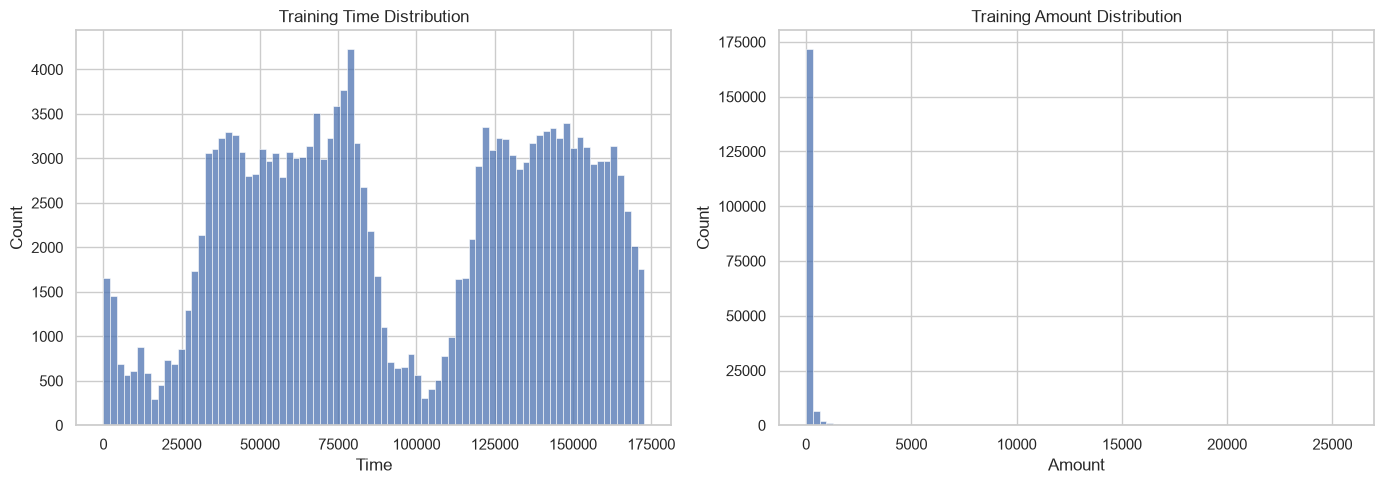

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    X_train["Time"],
    bins=80,
    ax=axes[0]
)

axes[0].set_title("Training Time Distribution")

sns.histplot(
    X_train["Amount"],
    bins=80,
    ax=axes[1]
)

axes[1].set_title("Training Amount Distribution")

plt.tight_layout()
plt.savefig(FIGURE_DIR / "time_amount_training_distribution.png")
plt.show()

In [23]:
from sklearn.preprocessing import StandardScaler, RobustScaler

standard_scaler = StandardScaler()
robust_scaler = RobustScaler()

standard_scaled = standard_scaler.fit_transform(
    X_train[["Time", "Amount"]]
)

robust_scaled = robust_scaler.fit_transform(
    X_train[["Time", "Amount"]]
)

print("StandardScaler mean:")
print(standard_scaled.mean(axis=0))

print("\nStandardScaler standard deviation:")
print(standard_scaled.std(axis=0))

print("\nRobustScaler median:")
print(np.median(robust_scaled, axis=0))

StandardScaler mean:
[-1.59669021e-16 -6.86077824e-18]

StandardScaler standard deviation:
[1. 1.]

RobustScaler median:
[0. 0.]


In [24]:

# Cell 22 — Verify saved preprocessing outputs

import os

required_files = [
    PROCESSED_DIR / "split_indices.npz",
    PROCESSED_DIR / "X_train.csv",
    PROCESSED_DIR / "X_val.csv",
    PROCESSED_DIR / "X_test.csv",
    PROCESSED_DIR / "y_train.csv",
    PROCESSED_DIR / "y_val.csv",
    PROCESSED_DIR / "y_test.csv",
]

for file_path in required_files:
    print(
        f"{'FOUND' if file_path.exists() else 'MISSING'}: "
        f"{file_path}"
    )


FOUND: ../data/processed/split_indices.npz
FOUND: ../data/processed/X_train.csv
MISSING: ../data/processed/X_val.csv
FOUND: ../data/processed/X_test.csv
FOUND: ../data/processed/y_train.csv
MISSING: ../data/processed/y_val.csv
FOUND: ../data/processed/y_test.csv


In [26]:

# Cell 25 — Save all train, validation and test partitions

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Save feature partitions
X_train.to_csv(PROCESSED_DIR / "X_train.csv", index=False)
X_val.to_csv(PROCESSED_DIR / "X_val.csv", index=False)
X_test.to_csv(PROCESSED_DIR / "X_test.csv", index=False)

# Save target partitions
y_train.rename("Class").to_frame().to_csv(
    PROCESSED_DIR / "y_train.csv", index=False
)
y_val.rename("Class").to_frame().to_csv(
    PROCESSED_DIR / "y_val.csv", index=False
)
y_test.rename("Class").to_frame().to_csv(
    PROCESSED_DIR / "y_test.csv", index=False
)

print("All six partition files saved successfully.")


All six partition files saved successfully.


In [27]:

# Cell 26 — Verify saved partition dimensions

for name in ["X_train", "X_val", "X_test"]:
    saved_data = pd.read_csv(PROCESSED_DIR / f"{name}.csv")
    print(f"{name}: {saved_data.shape}")

for name in ["y_train", "y_val", "y_test"]:
    saved_target = pd.read_csv(
        PROCESSED_DIR / f"{name}.csv"
    )["Class"]

    print(f"\n{name}:")
    print(saved_target.value_counts().sort_index())


X_train: (182276, 30)
X_val: (45570, 30)
X_test: (56961, 30)

y_train:
Class
0    181961
1       315
Name: count, dtype: int64

y_val:
Class
0    45491
1       79
Name: count, dtype: int64

y_test:
Class
0    56863
1       98
Name: count, dtype: int64
